# Deliverable 1: Data Collection, Cleaning, and Exploration

## Team supernova

This notebook explores the synthetic Healthcare Dataset published by Prasad22 on Kaggle. It inspects the data, documents cleaning decisions, and summarizes exploratory visualizations and findings.

**Dataset:** [Healthcare Dataset on Kaggle](https://www.kaggle.com/datasets/prasad22/healthcare-dataset)

**Important limitation:** The dataset creator describes these records as synthetic. Findings are for coursework and should not be interpreted as evidence about real patients, hospitals, or medical care.

Download the CSV and save it as `deliverable_1/data/healthcare_dataset.csv` (when running from the workspace root) or `data/healthcare_dataset.csv` (when running from this folder). Run the notebook from top to bottom.

## 1. Imports and data location

The next cell searches the two documented locations. If the file is absent, it stops with download instructions instead of silently substituting other data.

In [12]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

data_candidates = [
    Path('data/healthcare_dataset.csv'),
    Path('deliverable_1/data/healthcare_dataset.csv'),
    Path('../deliverable_1/data/healthcare_dataset.csv'),
]
data_path = next((path.resolve() for path in data_candidates if path.is_file()), None)

if data_path is None:
    expected = Path('deliverable_1/data/healthcare_dataset.csv')
    raise FileNotFoundError(
        'Healthcare CSV not found. Download it from '
        'https://www.kaggle.com/datasets/prasad22/healthcare-dataset '
        f'and save it as {expected} from the workspace root, or as '
        'data/healthcare_dataset.csv when running inside deliverable_1.'
    )

deliverable_dir = data_path.parent.parent
print(f'Loaded file path: {data_path}')

Loaded file path: /Users/nikitametha/datamining/deliverable_1/data/healthcare_dataset.csv


## 2. Load and inspect the raw data

Keep an untouched copy so that cleaning decisions can be traced back to the original values.

In [13]:
raw_df = pd.read_csv(data_path)
df = raw_df.copy(deep=True)

print(f'Rows: {len(df):,} | Columns: {df.shape[1]}')
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()}))
print(f'Exact duplicate rows: {df.duplicated().sum():,}')
display(df.describe(include='all').T)

Rows: 55,500 | Columns: 15


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


,dtype,missing
Name,object,0
Age,int64,0
Gender,object,0
Blood Type,object,0
Medical Condition,object,0
Date of Admission,object,0
Doctor,object,0
Hospital,object,0
Insurance Provider,object,0
Billing Amount,float64,0


Exact duplicate rows: 534


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,55500,49992,DAvId muNoZ,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,55500.0,NaN,NaN,NaN,51.539459,19.602454,13.0,35.0,52.0,68.0,89.0
Gender,55500,2,Male,27774,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Type,55500,8,A-,6969,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medical Condition,55500,6,Arthritis,9308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Admission,55500,1827,2024-03-16,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Doctor,55500,40341,Michael Smith,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hospital,55500,39876,LLC Smith,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Insurance Provider,55500,5,Cigna,11249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Billing Amount,55500.0,NaN,NaN,NaN,25539.316097,14211.454431,-2008.49214,13241.224652,25538.069376,37820.508436,52764.276736


Confirm that the downloaded file meets the assignment's minimum of 500 records and 8 attributes. Category listings help reveal inconsistent spellings or whitespace before normalization.

In [14]:
print(f'Meets 500-record requirement: {len(df) >= 500}')
print(f'Meets 8-attribute requirement: {df.shape[1] >= 8}')
if len(df) < 500 or df.shape[1] < 8:
    raise ValueError('The selected project requires at least 500 records and 8 attributes.')
print('\nOriginal column names:')
print(df.columns.tolist())

for column in df.select_dtypes(include='object').columns:
    values = df[column].dropna().astype(str).str.strip()
    print(f'\n{column}: {values.nunique()} distinct non-missing values')
    display(values.value_counts().head(10).rename('count').to_frame())

Meets 500-record requirement: True
Meets 8-attribute requirement: True

Original column names:
['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results']

Name: 49992 distinct non-missing values


,count
Name,
DAvId muNoZ,3
SOnYa aDams,2
terRY gONZaLeZ,2
JaCKsON BARbeR,2
doNALD aViLA,2
RICHARd cHERry,2
jeffRey davIs,2
BrEANnA JaMEs,2
MEgan mORriSon,2



Gender: 2 distinct non-missing values


,count
Gender,
Male,27774
Female,27726



Blood Type: 8 distinct non-missing values


,count
Blood Type,
A-,6969
A+,6956
AB+,6947
AB-,6945
B+,6945
B-,6944
O+,6917
O-,6877


... (14 outputs left out)


Medication: 5 distinct non-missing values


,count
Medication,
Lipitor,11140
Ibuprofen,11127
Aspirin,11094
Paracetamol,11071
Penicillin,11068



Test Results: 3 distinct non-missing values


,count
Test Results,
Abnormal,18627
Normal,18517
Inconclusive,18356


## 3. Standardize fields and clean the data

Column names become lowercase snake_case. Text values are trimmed and internal whitespace is collapsed; category capitalization is standardized for readability. Exact duplicate records are removed. Names, doctors, hospitals, and room numbers are retained in the cleaned source table but excluded from the analytical frame because they are identifiers or high-cardinality labels, not useful generalizable patient features.

In [15]:
def to_snake_case(value):
    """Convert a column label to lowercase snake_case."""
    value = str(value).strip().lower()
    value = re.sub(r'[^a-z0-9]+', '_', value)
    return value.strip('_')


df.columns = [to_snake_case(column) for column in df.columns]
print('Standardized column names:', df.columns.tolist())

# Trim whitespace while preserving canonical labels such as AB+ and UnitedHealthcare.
text_columns = df.select_dtypes(include='object').columns
for column in text_columns:
    values = df[column].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    df[column] = values

rows_before = len(df)
df = df.drop_duplicates().copy()
print(f'Removed {rows_before - len(df):,} exact duplicate rows after trimming text whitespace.')

# Convert known numeric fields; non-numeric entries become missing and are reported.
for column in ['age', 'billing_amount']:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')

# Treat impossible ages as invalid, but do not assume negative billing is an error.
if 'age' in df.columns:
    invalid_age = df['age'].notna() & ~df['age'].between(0, 120)
    print(f'Age values outside 0-120 set to missing: {invalid_age.sum():,}')
    df.loc[invalid_age, 'age'] = np.nan

# Parse dates and derive length of stay only when both source columns are available.
date_columns = ['date_of_admission', 'discharge_date']
for column in date_columns:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors='coerce')
        print(f'Unparseable or missing {column}: {df[column].isna().sum():,}')

if all(column in df.columns for column in date_columns):
    df['length_of_stay_days'] = (df['discharge_date'] - df['date_of_admission']).dt.days
    negative_stay = df['length_of_stay_days'] < 0
    print(f'Negative length-of-stay records set to missing: {negative_stay.sum():,}')
    df.loc[negative_stay, 'length_of_stay_days'] = np.nan

print('\nMissing values after type and date checks:')
display(df.isna().sum().sort_values(ascending=False).rename('missing').to_frame())

Standardized column names: ['name', 'age', 'gender', 'blood_type', 'medical_condition', 'date_of_admission', 'doctor', 'hospital', 'insurance_provider', 'billing_amount', 'room_number', 'admission_type', 'discharge_date', 'medication', 'test_results']
Removed 534 exact duplicate rows after trimming text whitespace.
Age values outside 0-120 set to missing: 0
Unparseable or missing date_of_admission: 0
Unparseable or missing discharge_date: 0
Negative length-of-stay records set to missing: 0

Missing values after type and date checks:


,missing
name,0
age,0
gender,0
blood_type,0
medical_condition,0
date_of_admission,0
doctor,0
hospital,0
insurance_provider,0
billing_amount,0


For exploratory analysis only, missing numeric measurements are filled with their median and missing non-target categories with `Unknown`. Missing dates and missing `test_results` are not imputed. This preserves the outcome label and avoids inventing event dates. The original, unmodified `raw_df` remains available for comparison.

In [16]:
identifier_columns = ['name', 'doctor', 'hospital', 'room_number']
target_like_columns = ['test_results']

# Impute numeric analysis fields with medians, recording each value used.
numeric_imputations = {}
for column in ['age', 'billing_amount', 'length_of_stay_days']:
    if column in df.columns and df[column].isna().any():
        median_value = df[column].median()
        if pd.notna(median_value):
            numeric_imputations[column] = median_value
            df[column] = df[column].fillna(median_value)

# Fill missing descriptive categories, but leave the target-like test result untouched.
categorical_columns = df.select_dtypes(include=['object', 'string', 'category']).columns
categorical_imputations = []
for column in categorical_columns:
    if column not in target_like_columns and column not in identifier_columns:
        if df[column].isna().any():
            df[column] = df[column].fillna('Unknown')
            categorical_imputations.append(column)

print('Numeric median imputations:', numeric_imputations)
print('Categorical fields filled with Unknown:', categorical_imputations)
print('\nRemaining missing values (dates, identifiers, and target labels may remain missing):')
display(df.isna().sum().sort_values(ascending=False).rename('missing').to_frame())

# Keep identifiers out of summaries and models; do not discard them from the cleaned source table.
analysis_df = df.drop(columns=[c for c in identifier_columns if c in df.columns]).copy()
print(f'Cleaned source shape: {df.shape}; analytical frame shape: {analysis_df.shape}')

Numeric median imputations: {}
Categorical fields filled with Unknown: []

Remaining missing values (dates, identifiers, and target labels may remain missing):


,missing
name,0
age,0
gender,0
blood_type,0
medical_condition,0
date_of_admission,0
doctor,0
hospital,0
insurance_provider,0
billing_amount,0


Cleaned source shape: (54966, 16); analytical frame shape: (54966, 12)


## 4. Investigate potential outliers

The IQR rule flags statistical extremes for review; it does not prove that a record is erroneous. Negative billing amounts are a separate semantic concern: they may represent adjustments, but the dataset provides no explanation. We report and retain them rather than automatically removing them.

In [17]:
outlier_rows = []
for column in ['age', 'billing_amount', 'length_of_stay_days']:
    if column in analysis_df.columns:
        values = analysis_df[column].dropna()
        if not values.empty:
            q1, q3 = values.quantile([0.25, 0.75])
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            count = ((values < lower) | (values > upper)).sum()
            outlier_rows.append({
                'feature': column,
                'lower_iqr_bound': lower,
                'upper_iqr_bound': upper,
                'flagged_count': int(count),
                'flagged_percent': 100 * count / len(values),
            })

if outlier_rows:
    display(pd.DataFrame(outlier_rows).set_index('feature'))
else:
    print('No available numeric fields for IQR review.')

if 'billing_amount' in analysis_df.columns:
    cleaned_negative_bills = analysis_df.loc[analysis_df['billing_amount'] < 0, 'billing_amount']
    if 'Billing Amount' in raw_df.columns:
        raw_negative_count = pd.to_numeric(raw_df['Billing Amount'], errors='coerce').lt(0).sum()
        print(f'Negative billing amounts in raw data: {raw_negative_count:,}')
    print(f'Negative billing amounts retained after duplicate removal: {len(cleaned_negative_bills):,}')
    if not cleaned_negative_bills.empty:
        print('Negative billing amount summary (retained; investigate meaning with source documentation):')
        display(cleaned_negative_bills.describe().to_frame('billing_amount'))

,lower_iqr_bound,upper_iqr_bound,flagged_count,flagged_percent
feature,,,,
age,-14.500000,117.500000,0,0.0
billing_amount,-23620.490637,74684.067437,0,0.0
length_of_stay_days,-14.500000,45.500000,0,0.0


Negative billing amounts in raw data: 108
Negative billing amounts retained after duplicate removal: 106
Negative billing amount summary (retained; investigate meaning with source documentation):


,billing_amount
count,106.000000
mean,-502.472497
std,429.857027
min,-2008.492140
25%,-803.004972
50%,-374.840042
75%,-149.074654
max,-23.866729


## 5. Exploratory data analysis

Plots are displayed inline in the notebook; no separate figures folder is created. Optional plots are skipped if their source columns are not present.

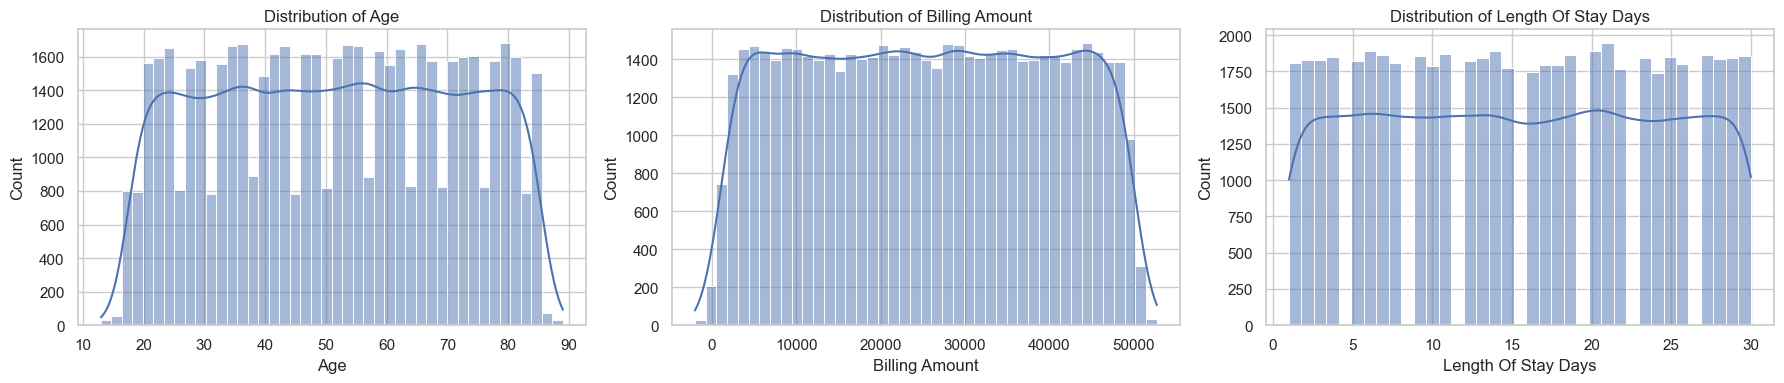

In [18]:
numeric_plot_columns = [
    column for column in ['age', 'billing_amount', 'length_of_stay_days']
    if column in analysis_df.columns
]
if numeric_plot_columns:
    fig, axes = plt.subplots(1, len(numeric_plot_columns), figsize=(6 * len(numeric_plot_columns), 4))
    axes = np.atleast_1d(axes)
    for ax, column in zip(axes, numeric_plot_columns):
        sns.histplot(data=analysis_df, x=column, kde=True, ax=ax)
        ax.set_title(f'Distribution of {column.replace("_", " ").title()}')
        ax.set_xlabel(column.replace('_', ' ').title())
    fig.tight_layout()
    plt.show()
else:
    print('No selected numeric fields are available to plot.')

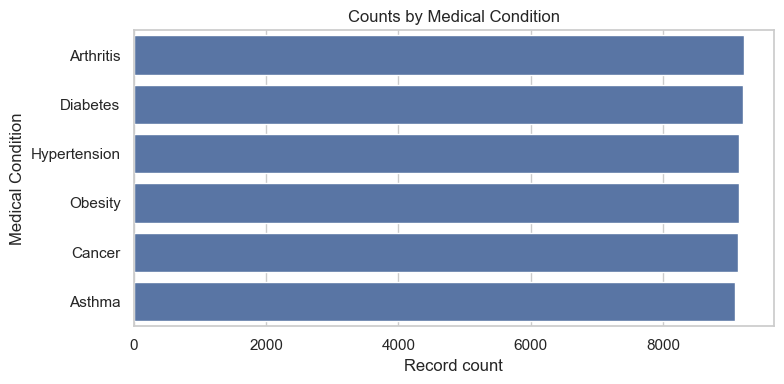

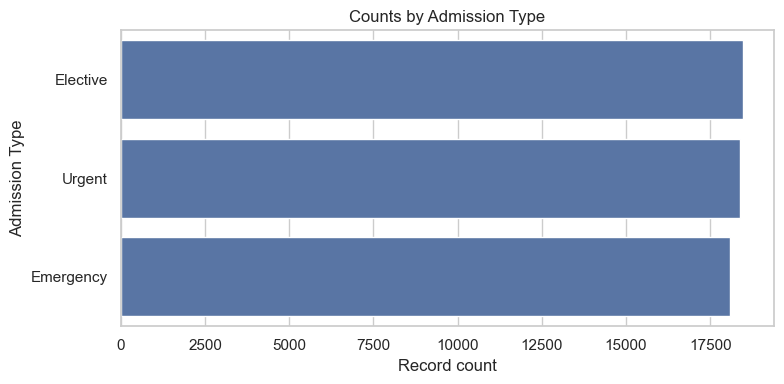

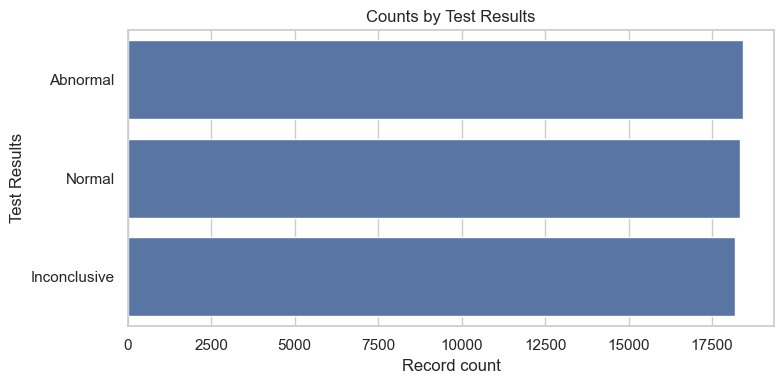

In [19]:
category_plot_columns = [
    column for column in ['medical_condition', 'admission_type', 'test_results']
    if column in analysis_df.columns
]
for column in category_plot_columns:
    counts = analysis_df[column].fillna('Missing').value_counts().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color=sns.color_palette()[0])
    ax.set_title(f'Counts by {column.replace("_", " ").title()}')
    ax.set_xlabel('Record count')
    ax.set_ylabel(column.replace('_', ' ').title())
    fig.tight_layout()
    plt.show()

if not category_plot_columns:
    print('No selected categorical fields are available to plot.')

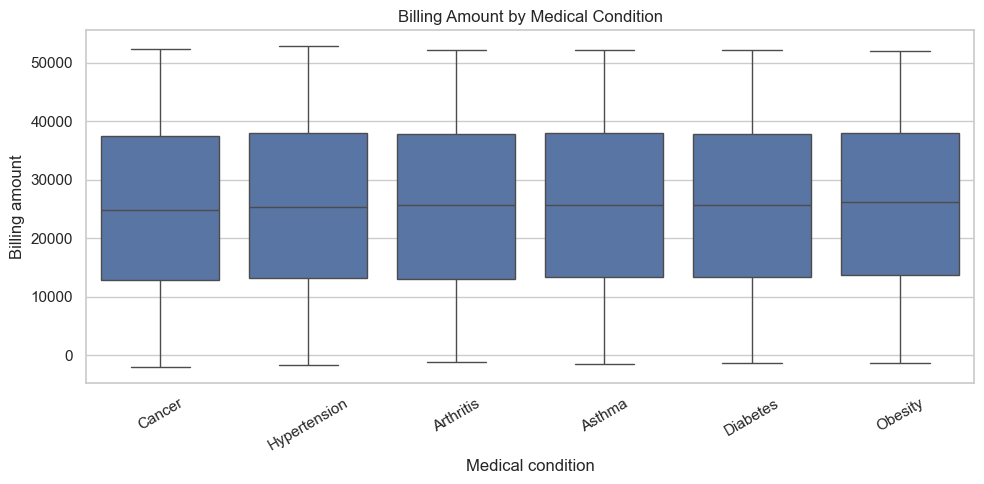

In [20]:
if {'billing_amount', 'medical_condition'}.issubset(analysis_df.columns):
    condition_order = analysis_df.groupby('medical_condition')['billing_amount'].median().sort_values().index
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(data=analysis_df, x='medical_condition', y='billing_amount', order=condition_order, ax=ax)
    ax.set_title('Billing Amount by Medical Condition')
    ax.set_xlabel('Medical condition')
    ax.set_ylabel('Billing amount')
    ax.tick_params(axis='x', rotation=30)
    fig.tight_layout()
    plt.show()
else:
    print('Skipped billing-by-condition plot: required fields are not both available.')

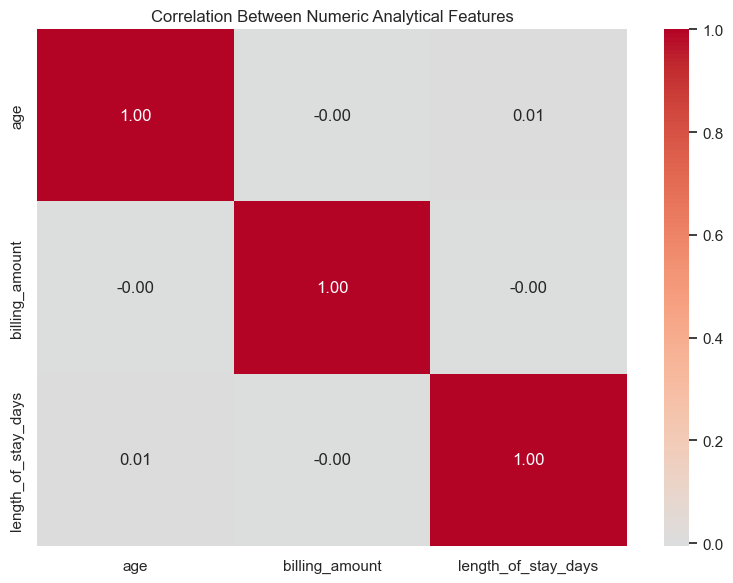

In [21]:
correlation_columns = analysis_df.select_dtypes(include=np.number).columns.tolist()
if len(correlation_columns) >= 2:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(analysis_df[correlation_columns].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
    ax.set_title('Correlation Between Numeric Analytical Features')
    fig.tight_layout()
    plt.show()
else:
    print('Skipped correlation heatmap: fewer than two numeric analytical features are available.')

## 6. Findings and interpretation

The following summaries are computed from the downloaded file rather than hard-coded, so they can be discussed after the notebook has been run. Relationships in this synthetic dataset are descriptive only, not clinical or causal evidence.

In [22]:
print(f'Final cleaned rows: {len(df):,}; analytical columns: {analysis_df.shape[1]}')
if 'test_results' in analysis_df.columns:
    print('\nTest-result distribution (including missing labels):')
    display(analysis_df['test_results'].fillna('Missing').value_counts(normalize=True).mul(100).round(1).rename('percent').to_frame())
if 'billing_amount' in analysis_df.columns:
    print('\nBilling amount summary:')
    display(analysis_df['billing_amount'].describe().to_frame())
if {'billing_amount', 'medical_condition'}.issubset(analysis_df.columns):
    print('\nMedian billing amount by condition (descriptive; synthetic data):')
    display(analysis_df.groupby('medical_condition')['billing_amount'].median().sort_values(ascending=False).to_frame('median_billing_amount'))

numeric_columns = analysis_df.select_dtypes(include=np.number).columns.tolist()
if len(numeric_columns) >= 2:
    correlation = analysis_df[numeric_columns].corr()
    upper_triangle = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
    strongest_pair = upper_triangle.abs().stack().sort_values(ascending=False)
    if not strongest_pair.empty:
        feature_a, feature_b = strongest_pair.index[0]
        value = correlation.loc[feature_a, feature_b]
        print(f'\nStrongest numeric correlation: {feature_a} and {feature_b} (r = {value:.3f}).')
        if abs(value) < 0.3:
            print('The available numeric features show no strong linear relationship; later predictive models should be compared with simple baselines.')

if 'test_results' in analysis_df.columns:
    result_shares = analysis_df['test_results'].value_counts(normalize=True, dropna=False)
    if len(result_shares) > 1:
        print(f"Test-result class share range: {result_shares.min():.1%} to {result_shares.max():.1%}; classes are relatively balanced.")



Final cleaned rows: 54,966; analytical columns: 12

Test-result distribution (including missing labels):


,percent
test_results,
Abnormal,33.5
Normal,33.3
Inconclusive,33.1



Billing amount summary:


,billing_amount
count,54966.000000
mean,25544.306284
std,14208.409711
min,-2008.492140
25%,13243.718641
50%,25542.749145
75%,37819.858159
max,52764.276736



Median billing amount by condition (descriptive; synthetic data):


,median_billing_amount
medical_condition,
Obesity,26145.578798
Diabetes,25647.705432
Asthma,25628.413135
Arthritis,25599.182892
Hypertension,25281.630443
Cancer,24910.709821



Strongest numeric correlation: age and length_of_stay_days (r = 0.008).
The available numeric features show no strong linear relationship; later predictive models should be compared with simple baselines.
Test-result class share range: 33.1% to 33.5%; classes are relatively balanced.


### What the plots show

- **Distributions.** Length of stay is spread fairly evenly across 1–30 days. The six medical conditions each account for about one-sixth of the cleaned admissions, and the three admission types are similarly balanced.
- **Billing by condition.** The boxplots overlap substantially. The median ranges from about $24,911 for Cancer to $26,146 for Obesity. The $1,235 gap between those medians is small relative to the overall billing interquartile range of about $24,576. The 106 negative bills retained after cleaning are an anomaly whose meaning is unknown.
- **Numeric relationships.** The largest absolute Pearson correlation between age, billing, and length of stay is about 0.008. This indicates very little linear association between those three fields. The heatmap compares them with each other, so it leaves their relationship with the categorical test outcome open.

### Test results by admission characteristics

**Modeling question.** At admission, how well can age and admission type predict whether the recorded test result will be Abnormal, Normal, or Inconclusive? Medical condition is included as an exploratory comparison. It would be eligible as a predictor if the recorded condition was known before the prediction.

The table uses admissions with a recorded test result. The percentages are calculated within each group, and the admission count shows the denominator. The last column gives the largest absolute difference between that group's three outcome rates and the corresponding rates for all labeled admissions, in percentage points.

In [23]:
labeled_admissions = analysis_df.dropna(subset=['test_results'])
test_results = labeled_admissions['test_results']
overall_rates = test_results.value_counts(normalize=True).mul(100)

age_groups = pd.cut(
    labeled_admissions['age'],
    bins=[0, 40, 60, 80, np.inf],
    labels=['0–39', '40–59', '60–79', '80+'],
    right=False,
).astype('string')

comparison_groups = {
    'Overall': pd.Series('All admissions', index=labeled_admissions.index),
    'Admission type': labeled_admissions['admission_type'],
    'Medical condition': labeled_admissions['medical_condition'],
    'Age (years)': age_groups,
}

group_summaries = {}
for feature, groups in comparison_groups.items():
    counts = pd.crosstab(groups.fillna('Missing'), test_results)
    counts = counts.reindex(columns=overall_rates.index, fill_value=0)
    admission_counts = counts.sum(axis=1)
    rates = counts.div(admission_counts, axis='index').mul(100)
    largest_gap = rates.sub(overall_rates, axis='columns').abs().max(axis=1)

    summary = rates.add_suffix(' (%)').round(2)
    summary.insert(0, 'Admissions', admission_counts)
    summary['Largest gap (pp)'] = largest_gap.round(2)
    group_summaries[feature] = summary

display(pd.concat(group_summaries, names=['Feature', 'Group']))

test_results                      Admissions  Abnormal (%)  Normal (%)  \
Feature           Group                                                  
Overall           All admissions       54966         33.54       33.35   
Admission type    Elective             18473         33.74       33.49   
                  Emergency            18102         33.36       33.39   
                  Urgent               18391         33.53       33.17   
Medical condition Arthritis             9218         34.24       32.55   
                  Asthma                9095         32.77       34.26   
                  Cancer                9140         33.80       33.02   
                  Diabetes              9216         33.97       33.21   
                  Hypertension          9151         32.53       33.94   
                  Obesity               9146         33.94       33.13   
Age (years)       0–39                 17710         33.24       34.09   
                  40–59                16308         33.83       32.81   
                  60–79                16098         33.63       33.30   
                  80+                   4850         33.42       32.60   

test_results                      Inconclusive (%)  Largest gap (pp)  
Feature           Group                                               
Overall           All admissions             33.11              0.00  
Admission type    Elective                   32.77              0.34  
                  Emergency                  33.26              0.19  
                  Urgent                     33.30              0.19  
Medical condition Arthritis                  33.22              0.80  
                  Asthma                     32.97              0.91  
                  Cancer                     33.18              0.33  
                  Diabetes                   32.81              0.43  
                  Hypertension               33.53              1.01  
                  Obesity                    32.93              0.40  
Age (years)       0–39                       32.67              0.74  
                  40–59                      33.36              0.54  
                  60–79                      33.07              0.08  
                  80+                        33.98              0.87

### Implications for modeling

- **The individual comparisons show only small differences.** No outcome rate for an admission type differs from its overall rate by more than 0.34 percentage points. The largest age-group gap is 0.87 points. Across conditions, the largest gap is for Abnormal results among hypertension admissions (32.53% compared with 33.54% overall). These group summaries suggest weak individual signals. They leave open whether a combination of features helps on held-out admissions.
- **Use an admission-time feature set.** Start with age and admission type. Verify when medical condition and medication were recorded before considering them as predictors. Exclude discharge date, length of stay, and the recorded billing amount from an admission-time model because their final values may incorporate information from later in the stay.
- **Compare with a baseline on later admissions.** Reserve the most recent admissions by admission date for evaluation and use earlier admissions to fit a majority-class baseline and a simple multinomial logistic regression. Abnormal accounts for about 33.5% of all labeled rows, which gives a reference point. Select the baseline class from the training rows and measure its actual accuracy on the held-out rows. Fit any preprocessing on the earlier admissions as part of the modeling pipeline. Report accuracy and macro F1 so each outcome class contributes equally to the latter metric.

Any measured predictive performance would describe this synthetic dataset.